In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
import sys
from pathlib import Path

# Identifica a raiz do projeto
BASE_DIR = Path.cwd().parent

# Adiciona a raiz do projeto ao caminho de importação
if str(BASE_DIR) not in sys.path:
    sys.path.insert(0, str(BASE_DIR))

print("Raiz do projeto:", BASE_DIR)

Raiz do projeto: c:\Users\dyego\Documents\Projetos\Olist Brazilian E-Commerce Dataset


In [3]:
import sys

print(sys.path)

['c:\\Users\\dyego\\Documents\\Projetos\\Olist Brazilian E-Commerce Dataset', 'C:\\Python312\\python312.zip', 'C:\\Python312\\DLLs', 'C:\\Python312\\Lib', 'C:\\Python312', 'c:\\Users\\dyego\\Documents\\Projetos\\Olist Brazilian E-Commerce Dataset\\.venv', '', 'c:\\Users\\dyego\\Documents\\Projetos\\Olist Brazilian E-Commerce Dataset\\.venv\\Lib\\site-packages']


In [4]:
from src.database import engine

In [5]:
# Consulta teste sql para verificar a conexão com o banco de dados

consulta = "Select * from analytics.orders;"

# Carrega os dados em um DataFrame
df_orders = pd.read_sql(consulta, con=engine)

df_orders.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26


In [6]:
df_orders.shape

(99441, 8)

In [7]:
consulta = 'select * from analytics.order_items;'

df_items = pd.read_sql(consulta, con=engine)

df_items.head()

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


In [8]:
df_items.shape

(112650, 7)

In [9]:
print(f'valores de tabela "orders"[order_id] duplicados: {df_orders['order_id'].duplicated().sum()}')
print(f'valores da tabela "order_items"[order_id] unicos: {df_items['order_id'].nunique()}')

valores de tabela "orders"[order_id] duplicados: 0
valores da tabela "order_items"[order_id] unicos: 98666


In [10]:
df_orders_delivered = df_orders[df_orders['order_status'] == 'delivered'] 
df_orders_delivered.shape

(96478, 8)

### merge() -> Criação de df_vendas, contendo somente os items associados a pedidos entregues

In [11]:
# União de dataframe 
df_vendas = pd.merge(df_orders_delivered, df_items, on= "order_id", how='inner', validate='one_to_many')
df_vendas.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,1,87285b34884572647811a353c7ac498a,3504c0cb71d7fa48d967e0e4c94d59d9,2017-10-06 11:07:15,29.99,8.72
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,1,595fac2a385ac33a80bd5114aec74eb8,289cdb325fb7e7f891c38608bf9e0962,2018-07-30 03:24:27,118.70,22.76
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,1,aa4383b373c6aca5d8797843e5594415,4869f7a5dfa277a7dca6462dcf3b52b2,2018-08-13 08:55:23,159.90,19.22
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,1,d0b61bfb1de832b15ba9d266ca96e5b0,66922902710d126a0e7d26b0e3805106,2017-11-23 19:45:59,45.00,27.20
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,1,65266b2da20d04dbe00c5c2d3bb7859e,2c9e548be18521d1c43cde1c582c6de8,2018-02-19 20:31:37,19.90,8.72


In [12]:
df_vendas.shape

(110197, 14)

In [13]:
# Pedidos unicos
unicos = df_vendas['order_id'].nunique()
unicos


96478

### Indicadores Comerciais


In [14]:
# Calculo de total de produtos vendidos, sem frete
total_vendas = df_vendas['price'].sum()
print(f'Valor total de venda sem frete: {total_vendas:,.2f}')
# Calculo de total de frete do produtos vendidos, sem valor de venda
total_frete = df_vendas['freight_value'].sum()
print(f'Valor total de frete: {total_frete:,.2f}')
# Calculo de total arrecadado com vendas
print(f'Valor total arrecadado com vendas: {(total_vendas + total_frete):,.2f}')

Valor total de venda sem frete: 13,221,498.11
Valor total de frete: 2,198,275.64
Valor total arrecadado com vendas: 15,419,773.75


In [15]:
# Ticket Médio

ticket_medio = (total_vendas + total_frete) / unicos
print(f'Ticket Médio = {ticket_medio:,.2f}')

Ticket Médio = 159.83


### Evolução mensal das vendas

In [16]:
df_vendas['order_purchase_timestamp'].dtype

df_vendas['ano_mes'] = df_vendas['order_purchase_timestamp'].dt.to_period('M')
df_vendas.head()
df_vendas.shape

(110197, 15)

In [17]:
# Agrupamento -> Valor de vendas por mês
vendas_mensais = df_vendas.groupby('ano_mes')['price'].sum()
print(vendas_mensais.map(lambda valor: f'{valor:,.2f}').head())
print(type(vendas_mensais))

ano_mes
2016-09        134.97
2016-10     40,325.11
2016-12         10.90
2017-01    111,798.36
2017-02    234,223.40
Freq: M, Name: price, dtype: str
<class 'pandas.Series'>


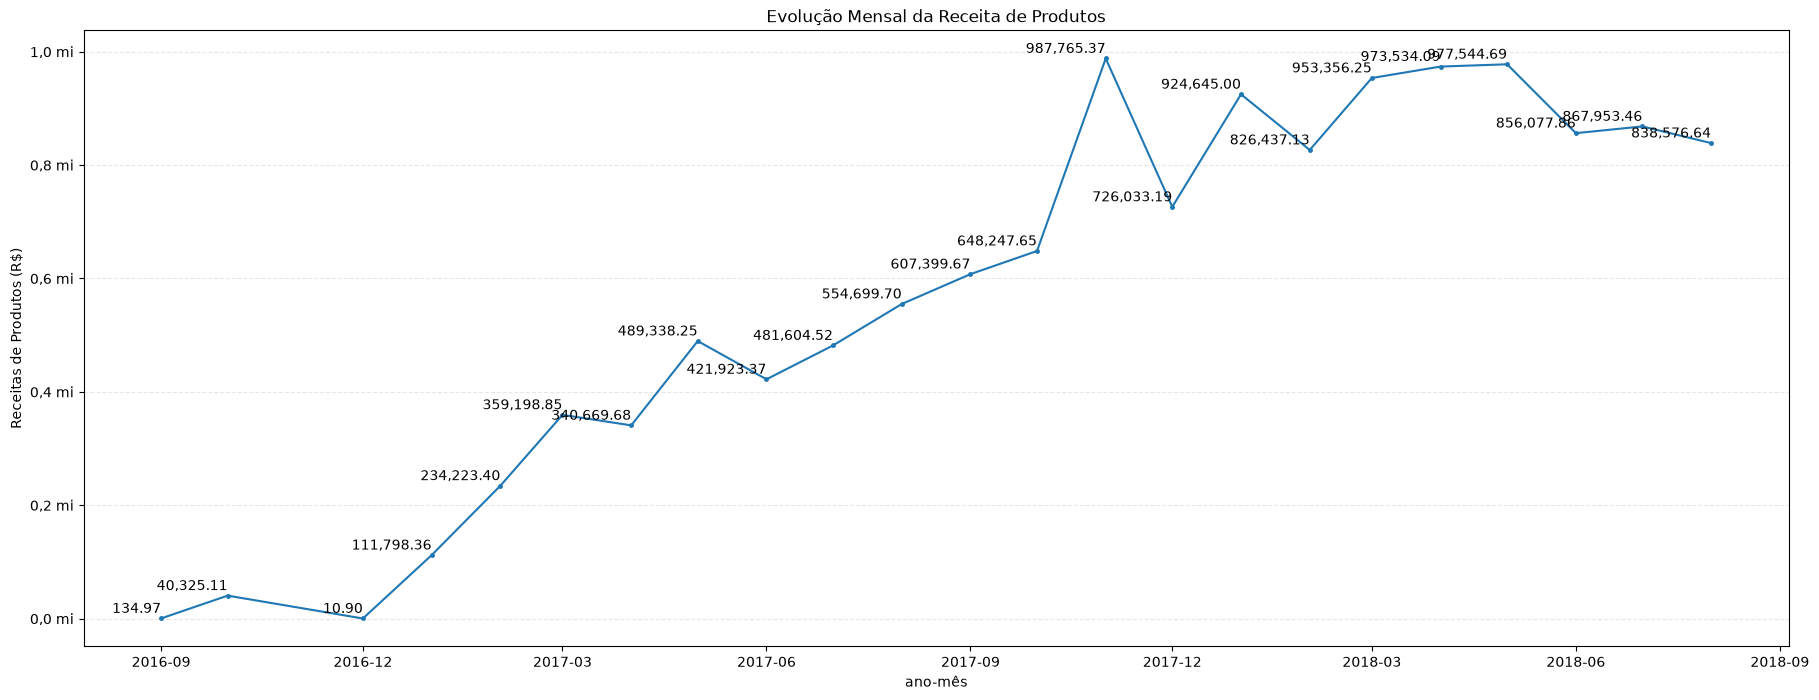

In [18]:
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter

# Formatador de datas
formatador = mdates.DateFormatter('%Y-%m')
localizador = mdates.MonthLocator(interval=3)

# Formatador de valores
formatador_valores = FuncFormatter(lambda valor, posicao: f'{valor /1_000_000:.1f} mi'.replace('.',','))


# Plotando
plt.figure(figsize=(22,8))
plt.title('Evolução Mensal da Receita de Produtos')
plt.plot(vendas_mensais.index.to_timestamp(), vendas_mensais.values, marker= '.', markersize=5)
plt.xlabel('ano-mês')
plt.ylabel('Receitas de Produtos (R$)')
plt.gca().xaxis.set_major_locator(localizador)
plt.gca().xaxis.set_major_formatter(formatador)
plt.gca().yaxis.set_major_formatter(formatador_valores)
for mes, receita in zip(vendas_mensais.index.to_timestamp(), vendas_mensais.values):
    plt.annotate(
        text= str(f'{receita:,.2f}') ,
        xy = (mes, receita),
        xytext=(0,4),
        textcoords='offset points',
        ha = 'right'
    )
plt.grid(axis='y', linestyle = '--', alpha = 0.3)
plt.show()

In [19]:
df_vendas['order_purchase_timestamp'].dtype

df_vendas['ano_mes'] = df_vendas['order_purchase_timestamp'].dt.to_period('M')
df_vendas.head()
df_vendas.shape

(110197, 15)

In [25]:
maior_receita = vendas_mensais.max()
mes_maior_receita = vendas_mensais.idxmax()
mes_maior_receita = mes_maior_receita.to_timestamp()

def formatar_valor(valor):
    return f'R$ {valor:,.2f}'.replace(',', 'X').replace('.', ',').replace('X', '.')

print(f'Maior receita: {formatar_valor(maior_receita)}')
print(f'Mês de Maior receita: {mes_maior_receita}')

Maior receita: R$ 987.765,37
Mês de Maior receita: 2017-11-01 00:00:00


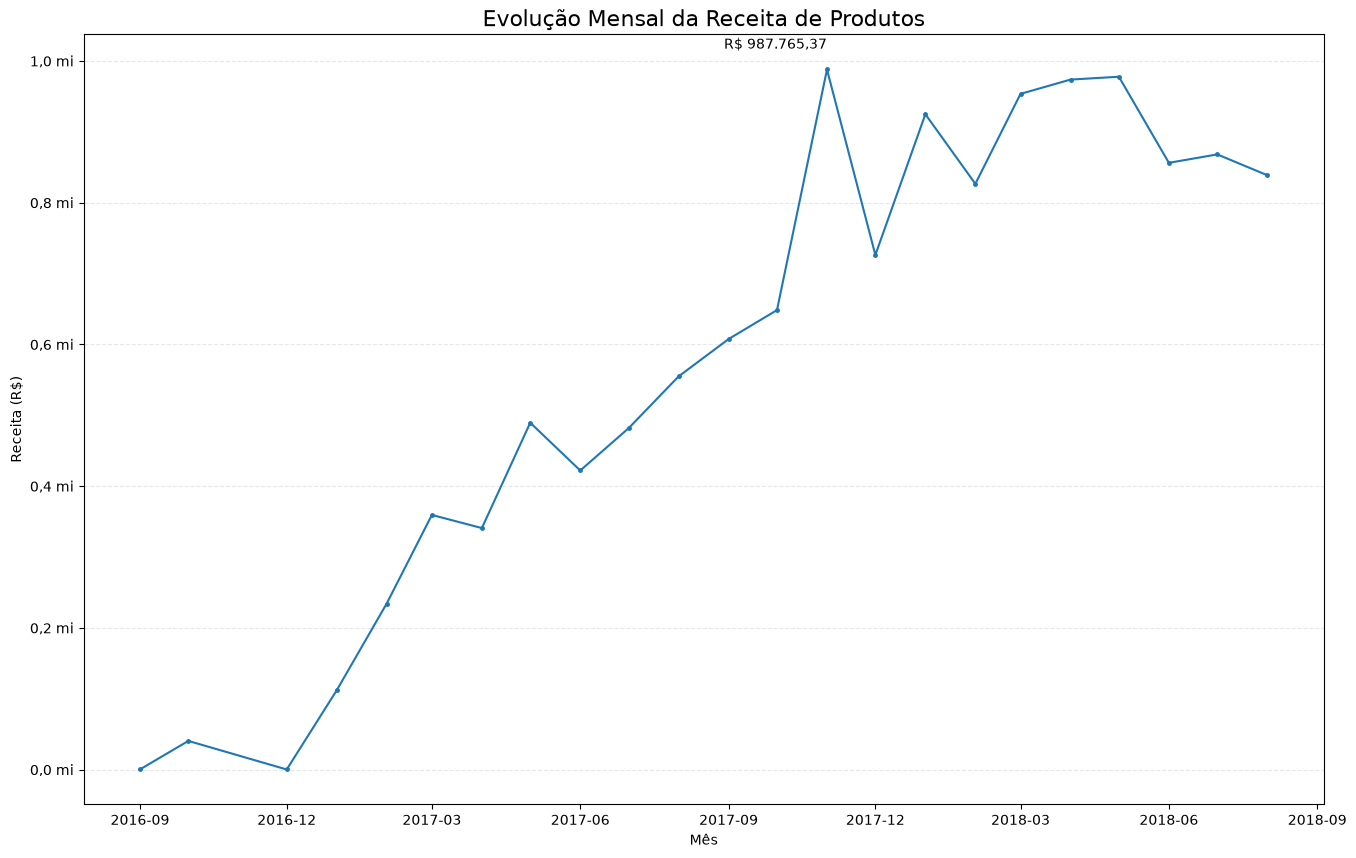

In [52]:
plt.figure(figsize=(16,10))
plt.title('Evolução Mensal da Receita de Produtos', ha='center', fontsize=16)
plt.plot(vendas_mensais.index.to_timestamp(), vendas_mensais.values, marker= '.', markersize=5)
plt.xlabel('Mês')
plt.ylabel('Receita (R$)')
plt.gca().xaxis.set_major_locator(localizador)
plt.gca().xaxis.set_major_formatter(formatador)
plt.gca().yaxis.set_major_formatter(formatador_valores)
plt.annotate(
        text=formatar_valor(maior_receita),
        xy = (mes_maior_receita, maior_receita),
        xytext=(0,15),
        textcoords='offset points',
        ha = 'right'
    )
plt.grid(axis='y', linestyle = '--', alpha = 0.3)
plt.show()

### Quais são as 10 categorias com maior receita?

* identificar as categorias de produtos que mais contribuem para a receita de itens dos pedidos entregues.

In [55]:
consulta = 'select * from analytics.products;'

df_products = pd.read_sql(consulta, con=engine)

df_products.head()

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.0,250.0,1.0,154.0,18.0,9.0,15.0
3,cef67bcfe19066a932b7673e239eb23d,bebes,27.0,261.0,1.0,371.0,26.0,4.0,26.0
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37.0,402.0,4.0,625.0,20.0,17.0,13.0


In [57]:
print(df_products.shape)
print(df_products.info())

(32951, 9)
<class 'pandas.DataFrame'>
RangeIndex: 32951 entries, 0 to 32950
Data columns (total 9 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   product_id                  32951 non-null  str    
 1   product_category_name       32341 non-null  str    
 2   product_name_lenght         32341 non-null  float64
 3   product_description_lenght  32341 non-null  float64
 4   product_photos_qty          32341 non-null  float64
 5   product_weight_g            32949 non-null  float64
 6   product_length_cm           32949 non-null  float64
 7   product_height_cm           32949 non-null  float64
 8   product_width_cm            32949 non-null  float64
dtypes: float64(7), str(2)
memory usage: 2.3 MB
None


In [58]:

df_vendas_products = pd.merge(df_vendas, df_products[['product_id', 'product_category_name']],
                              on= 'product_id', how='left', validate='many_to_one')